# Week 7: Hands-On ML Solution Data Visualizations

## Dataset 2: Customer Transactions

### 1. Introduction

In this notebook, our team explores customer purchasing activity using the preprocessed customer transactions dataset from Milestone 1. The analysis focuses on transaction amounts, product categories, payment methods, and monthly transaction activity. Through descriptive statistics and visualizations, we aim to identify patterns and observations that may support future machine learning tasks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Loading the Cleaned Dataset

The preprocessed customer transactions dataset from Milestone 1 is loaded into the notebook. This allows our team to focus on exploratory data analysis and visualization using the cleaned records rather than repeating the preprocessing steps.

In [2]:
transactions = pd.read_csv(
    "../week3_preprocessing_submission/customer_transactions_preprocessed.csv"
)

In [3]:
print("Transaction Amount Verification:")

print("Minimum:", transactions["Amount"].min())
print("Maximum:", transactions["Amount"].max())
print("Mean:", transactions["Amount"].mean())
print("Median:", transactions["Amount"].median())

print("\nNegative amounts:", (transactions["Amount"] < 0).sum())
print("Zero amounts:", (transactions["Amount"] == 0).sum())

Transaction Amount Verification:
Minimum: 10.03
Maximum: 999.86
Mean: 504.80944278606967
Median: 508.0700000000001

Negative amounts: 0
Zero amounts: 0


### 3. Dataset Validation and Initial Inspection

We will examine the dataset's structure, column names, data types, missing values, and duplicate records. We will also review the transaction amount statistics to confirm that the preprocessed dataset is ready for exploratory data analysis and visualization.

In [5]:
display(transactions.head())

print("Dataset shape:", transactions.shape)

print("\nColumn names:")
print(transactions.columns.tolist())

print("\nData types:")
print(transactions.dtypes)

print("\nMissing values:")
print(transactions.isnull().sum())

print("\nDuplicate rows:", transactions.duplicated().sum())

,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
0,60567026-f719-4cd6-849e-137e86d8938f,5ff75116-0a50-4d04-80fb-31e5ccbb0769,2024-05-15,117.64,Clothing,PayPal
1,4090ba85-b111-4f75-a792-c777965f5255,2c39b9fe-ff57-4d39-9321-9f5cdf187aa1,2023-04-26,466.14,Health & Beauty,Bank Transfer
2,9223891b-73ff-4d5c-b8ae-13ece82ee28b,f79588dd-3db9-4ffa-97f8-7de0e64259f1,2022-09-23,563.99,Clothing,Debit Card
3,9243eebc-938f-480c-8564-16d503d250de,401c0fc9-60df-4455-ad78-67c132f9897d,2024-04-15,254.44,Automotive,PayPal
4,6e3e8eb8-bc0f-4ffe-9f74-5d5efec9502f,2034aebc-8280-4254-a667-92bcd1c2be4f,2024-03-06,590.52,Home & Garden,Bank Transfer


Dataset shape: (3015, 6)

Column names:
['CustomerID', 'TransactionID', 'TransactionDate', 'Amount', 'ProductCategory', 'PaymentMethod']

Data types:
CustomerID             str
TransactionID          str
TransactionDate        str
Amount             float64
ProductCategory        str
PaymentMethod          str
dtype: object

Missing values:
CustomerID         0
TransactionID      0
TransactionDate    0
Amount             0
ProductCategory    0
PaymentMethod      0
dtype: int64

Duplicate rows: 0


### 4. Descriptive Statistics of Transaction Amounts

This section calculates descriptive statistics for the 3,015 transaction records to understand the distribution and variability of transaction amounts. The analysis includes the mean, median, standard deviation, variance, minimum, maximum, range, and quartiles. These measures provide an overview of typical transaction values and the spread of customer spending amounts.

In [6]:
amount = pd.to_numeric(
    transactions["Amount"],
    errors="coerce"
).dropna().to_numpy()

amount_statistics = {
    "Valid Amount Count": len(amount),
    "Mean": np.mean(amount),
    "Median": np.median(amount),
    "Standard Deviation": np.std(amount, ddof=1),
    "Variance": np.var(amount, ddof=1),
    "Minimum": np.min(amount),
    "Maximum": np.max(amount),
    "Range": np.ptp(amount),
    "25th Percentile": np.percentile(amount, 25),
    "75th Percentile": np.percentile(amount, 75)
}

for statistic, value in amount_statistics.items():
    if statistic == "Valid Amount Count":
        print(f"{statistic}: {value}")
    else:
        print(f"{statistic}: {value:,.2f}")

Valid Amount Count: 3015
Mean: 504.81
Median: 508.07
Standard Deviation: 270.29
Variance: 73,057.71
Minimum: 10.03
Maximum: 999.86
Range: 989.83
25th Percentile: 282.02
75th Percentile: 720.39


### 5. Visualization 1: Transaction Amount Distribution

The histogram illustrates the distribution of transaction amounts across the 3,015 records. The values are spread across a range of approximately 10 to 1,000, with a noticeable concentration around 500. This peak is likely influenced by the median imputation performed during preprocessing, where missing transaction amounts were replaced with the median value of the dataset. The visualization helps us understand the overall distribution of customer transaction amounts and identify patterns that may be relevant to further analysis.

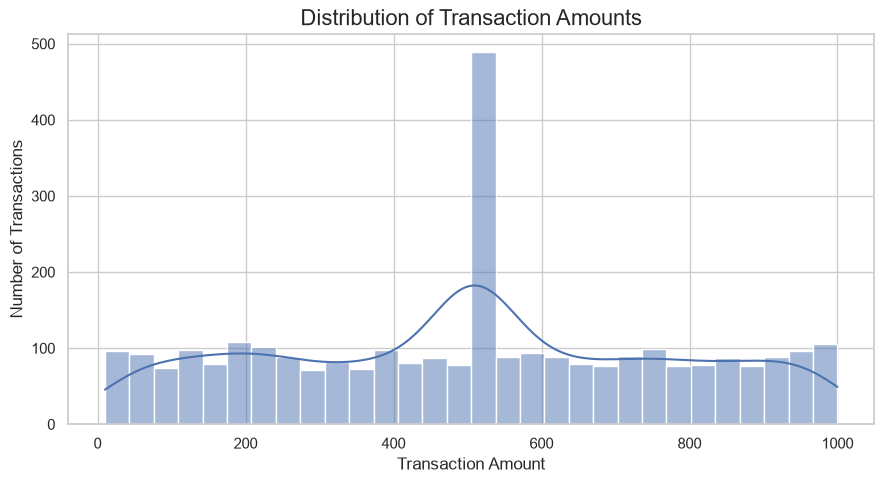

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=transactions,
    x="Amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Transaction Amounts", fontsize=16)
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Key Observation:

Transaction amounts are distributed across the available range, but a prominent peak appears around 500. This concentration is consistent with the median value used to replace missing transaction amounts during preprocessing. Therefore, the peak should not automatically be interpreted as evidence that customers commonly make transactions of exactly this amount.

### 7. Visualization 2: Transaction Amount Outliers

The boxplot illustrates the distribution and spread of transaction amounts in the cleaned dataset. The median is approximately 508.07, while the middle 50% of transaction values fall between 282.02 and 720.39. The whiskers extend from approximately 10.03 to 999.86. No separate outlier points are displayed using the boxplot's default outlier criteria. This suggests that the transaction amounts do not contain statistically identified extreme values under this method.

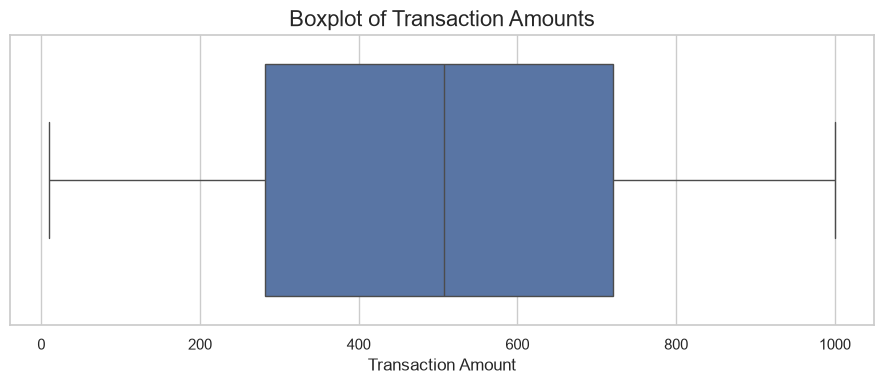

In [8]:
plt.figure(figsize=(9, 4))

sns.boxplot(data=transactions, x="Amount")

plt.title("Boxplot of Transaction Amounts", fontsize=16)
plt.xlabel("Transaction Amount")
plt.tight_layout()
plt.show()

### Key Observation:

The boxplot shows that transaction amounts are widely distributed, with a median of approximately 508.07. The middle 50% of transactions range from 282.02 to 720.39. No separate outliers are visible based on the default boxplot criteria. However, this does not necessarily mean that all transaction values are normal or free from data-quality issues.

### 9. Visualization 3: Transactions by Product Category

This bar chart compares the number of transactions across the different product categories. Clothing has the highest transaction count, followed by Electronics. Automotive, Home & Garden, and Health & Beauty have relatively similar counts. The Unknown category has noticeably fewer transactions than the other categories. These results show that transaction activity is distributed across several product categories, although Clothing and Electronics have slightly higher counts.

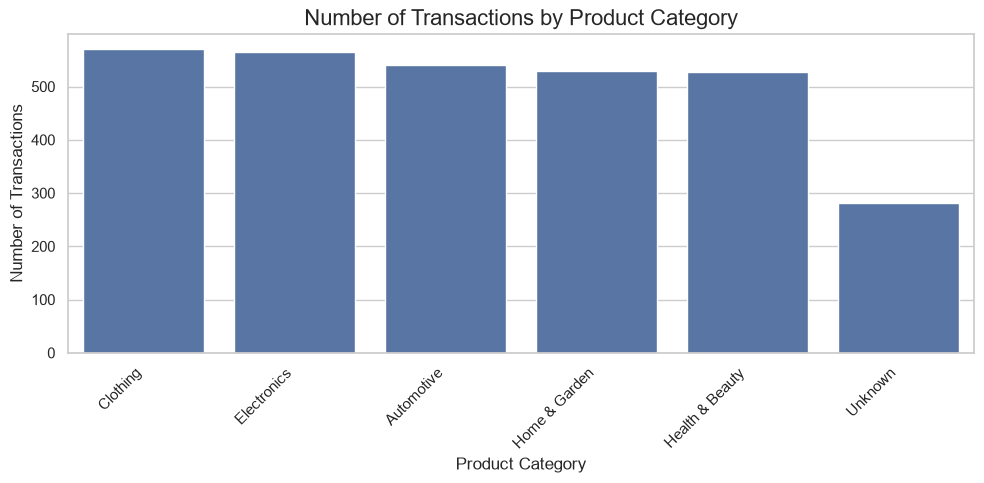

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=transactions,
    x="ProductCategory",
    order=transactions["ProductCategory"].value_counts().index
)

plt.title("Number of Transactions by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Key Observation:

Clothing and Electronics are the two most frequently recorded product categories. Automotive, Home & Garden, and Health & Beauty have relatively comparable transaction counts. The Unknown category has a lower count, indicating that some transactions do not have a specified product category. This missing category information should be considered in future customer behavior analysis and machine learning preparation.

### 11. Visualization 4: Transactions by Payment Method

This bar chart compares the frequency of transactions across the four available payment methods. Debit Card has the highest number of transactions, followed by Credit Card and PayPal. Bank Transfer has the lowest count. However, the differences between the four payment methods are relatively small, indicating that transaction activity is fairly balanced across the available payment options.

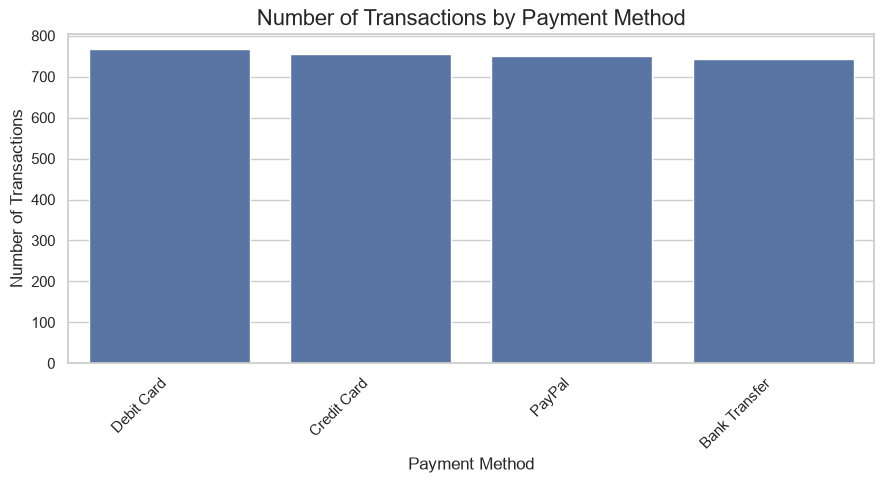

In [10]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=transactions,
    x="PaymentMethod",
    order=transactions["PaymentMethod"].value_counts().index
)

plt.title("Number of Transactions by Payment Method", fontsize=16)
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Key Observation:

Debit Card is the most frequently recorded payment method, while Bank Transfer has the lowest transaction count. Credit Card and PayPal also show similar levels of usage. Overall, the distribution suggests that customers use different payment methods without one option overwhelmingly dominating the others. These findings may help support future analysis of customer payment preferences.

### 13. Visualization 5: Monthly Transaction Trends

This line chart illustrates the monthly number of transactions from January 2022 to January 2025. Transaction activity was relatively low during the first half of 2022, with approximately 17 to 31 transactions per month. A substantial increase occurred around July 2022, followed by higher activity throughout 2023 and the first half of 2024. Monthly transactions fluctuated during this period, reaching a peak of approximately 142 transactions in August 2023. A sharp decline is visible beginning around July 2024, when monthly transactions dropped to approximately 29 and remained considerably lower through January 2025.

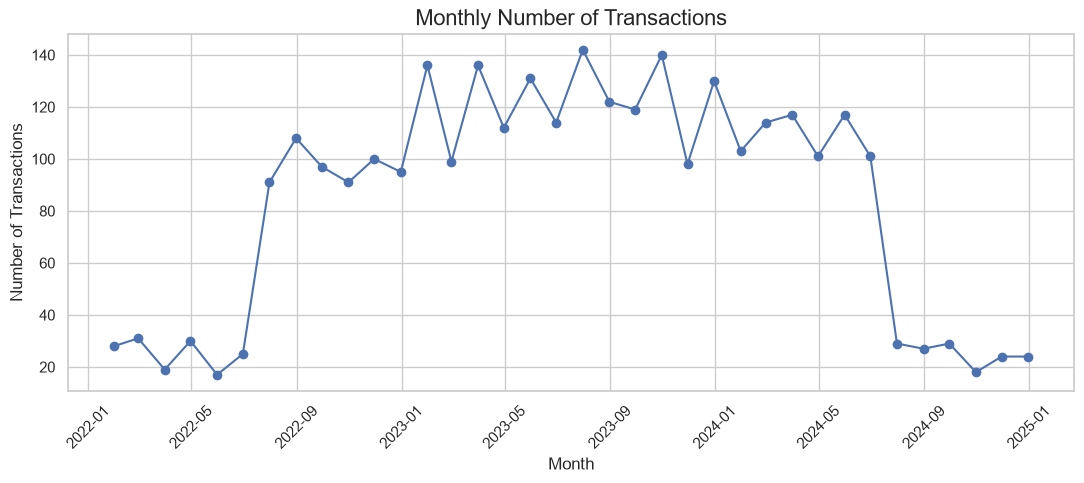

In [11]:
# Convert the transaction date into datetime format
transactions["TransactionDate"] = pd.to_datetime(
    transactions["TransactionDate"],
    errors="coerce"
)

# Group transactions by month
monthly_transactions = (
    transactions.dropna(subset=["TransactionDate"])
    .set_index("TransactionDate")
    .resample("ME")
    .size()
)

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_transactions.index,
    monthly_transactions.values,
    marker="o"
)

plt.title("Monthly Number of Transactions", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Key Observation:

The chart shows a noticeable change in transaction activity over the observed period. Monthly transactions increased significantly around July 2022 and remained relatively high throughout 2023 and the first half of 2024. However, transaction counts dropped sharply beginning in July 2024 and remained low through January 2025. This decline should be investigated further to determine whether it reflects an actual change in purchasing activity or incomplete transaction records. The pattern may be useful for future time-based customer behavior analysis.

## 15. Overall Findings and Machine Learning Relevance

The analysis shows that transaction amounts are widely distributed, with a median of approximately 508.07. Clothing and Electronics have the highest transaction counts, while the four payment methods show relatively similar levels of usage. The monthly transaction analysis also reveals increased activity from the second half of 2022 through the first half of 2024, followed by a sharp decline beginning in July 2024. These findings provide useful information for understanding customer purchasing behavior, product preferences, payment methods, and transaction patterns over time.

The cleaned dataset contains 3,015 transaction records, with no remaining missing values or exact duplicate rows. However, the Unknown product category and the sharp decline in monthly transaction counts should still be considered during further analysis. These findings can support future machine learning work, particularly customer segmentation and the identification of purchasing behavior patterns. Before modeling, the transaction data should be integrated with customer demographic and social media information using an appropriate customer-level aggregation process.